# Aula 6 - Árvores de decisão e métodos de conjunto com a Olist

**Business Intelligence e Análise Preditiva - Centro Universitário SENAC - Prof. Pedro Ernesto da Silva Souza**

Perguntas de negócio:
1. **Qual a probabilidade de o pedido atrasar?** (mesmo alvo da Aula 5, agora com árvores e conjuntos)
2. **Qual a probabilidade de o cliente dar nota baixa (1 ou 2)?** (novo alvo - `avaliacao_baixa`)

Roteiro: árvore de decisão (desenho, regras, sobreajuste) → random forest e gradient boosting → importância de variáveis → validação cruzada e busca em grade → segundo alvo → métricas por região (ética).

Execute as células na ordem. Complete os trechos **TODO**. Dupla: ______________________

## 1. Configuração e dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, time
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
SEMENTE = 42
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.2 | scikit-learn 1.5.1


In [2]:
import os
CAMINHO = "../datasets/olist/olist_modelagem.csv"
if not os.path.exists(CAMINHO):
    try:
        from google.colab import files
        print("Selecione o arquivo olist_modelagem.csv (pacote Olist)")
        files.upload()
    except ImportError:
        pass
df = pd.read_csv(CAMINHO)
print(df.shape, "| taxa de atraso:", round(df["atrasado"].mean(), 4), "| taxa de avaliação baixa:", round(df["avaliacao_baixa"].mean(), 4))

(96470, 28) | taxa de atraso: 0.0811 | taxa de avaliação baixa: 0.1315


## 2. Preparação (as 20 variáveis do modelo ampliado da Aula 5)

Árvores não precisam de escala; o pré-processador das árvores só imputa e codifica. A logística continua com padronização.

In [3]:
numericas = ["dias_estimados", "mesmo_estado", "frete_total", "peso_total_g", "n_itens", "dias_aprovacao", "mes_compra", "hora_compra",
             "dia_semana_compra", "preco_total", "volume_total_cm3", "fotos_media", "descricao_media", "parcelas", "valor_pago", "n_vendedores"]
categoricas = ["customer_state", "seller_state", "categoria_principal", "payment_type"]

def onehot():
    return OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False)

def criar_preprocessador_arvore(num=None, cat=None):
    num = num or numericas; cat = cat or categoricas
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                              ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("onehot", onehot())]), cat)])

def criar_preprocessador_linear(num=None, cat=None):
    num = num or numericas; cat = cat or categoricas
    return ColumnTransformer([("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), num),
                              ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("onehot", onehot())]), cat)])

X = df[numericas + categoricas]
y = df["atrasado"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE, stratify=y)
print(f"treino {len(y_treino)} ({y_treino.mean():.2%} atrasados) | teste {len(y_teste)} ({y_teste.mean():.2%})")

def avaliar(nome, modelo, Xte=None, yte=None, limiar=0.5):
    Xte = X_teste if Xte is None else Xte; yte = y_teste if yte is None else yte
    prob = modelo.predict_proba(Xte)[:, 1]; pred = (prob >= limiar).astype(int)
    linha = {"modelo": nome, "AUC": roc_auc_score(yte, prob), "recall": recall_score(yte, pred),
             "precisão": precision_score(yte, pred, zero_division=0), "F1": f1_score(yte, pred), "acurácia": accuracy_score(yte, pred)}
    print(f"{nome:34s} AUC {linha['AUC']:.3f} | recall {linha['recall']:.3f} | precisão {linha['precisão']:.3f} | F1 {linha['F1']:.3f} | acurácia {linha['acurácia']:.3f}")
    return linha, prob

treino 77176 (8.11% atrasados) | teste 19294 (8.11%)


## 3. Árvore de decisão

Começamos por uma árvore pequena (profundidade 3), que cabe em um slide e se lê como regras.

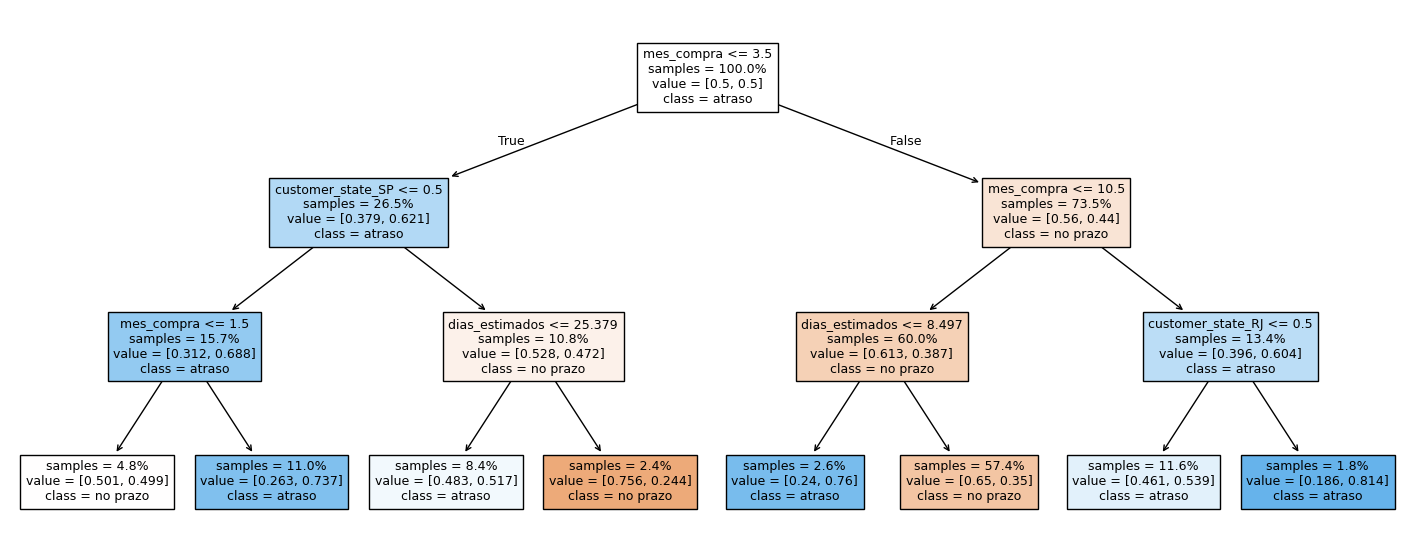

|--- mes_compra <= 3.50
|   |--- customer_state_SP <= 0.50
|   |   |--- mes_compra <= 1.50
|   |   |   |--- class: 0
|   |   |--- mes_compra >  1.50
|   |   |   |--- class: 1
|   |--- customer_state_SP >  0.50
|   |   |--- dias_estimados <= 25.38
|   |   |   |--- class: 1
|   |   |--- dias_estimados >  25.38
|   |   |   |--- class: 0
|--- mes_compra >  3.50
|   |--- mes_compra <= 10.50
|   |   |--- dias_estimados <= 8.50
|   |   |   |--- class: 1
|   |   |--- dias_estimados >  8.50
|   |   |   |--- class: 0
|   |--- mes_compra >  10.50
|   |   |--- customer_state_RJ <= 0.50
|   |   |   |--- class: 1
|   |   |--- customer_state_RJ >  0.50
|   |   |   |--- class: 1

Árvore profundidade 3              AUC 0.684 | recall 0.620 | precisão 0.144 | F1 0.234 | acurácia 0.671


In [4]:
arvore3 = Pipeline([("pre", criar_preprocessador_arvore()), ("clf", DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMENTE))])
arvore3.fit(X_treino, y_treino)
nomes = [n.split("__")[1] for n in arvore3.named_steps["pre"].get_feature_names_out()]
plt.figure(figsize=(18, 7))
plot_tree(arvore3.named_steps["clf"], feature_names=nomes, class_names=["no prazo", "atraso"], filled=True, impurity=False, proportion=True, fontsize=9)
plt.show()
print(export_text(arvore3.named_steps["clf"], feature_names=nomes, decimals=2))
_ = avaliar("Árvore profundidade 3", arvore3)

### Sobreajuste: o que acontece sem limite de profundidade

In [5]:
t0 = time.time()
arvore_livre = Pipeline([("pre", criar_preprocessador_arvore()), ("clf", DecisionTreeClassifier(random_state=SEMENTE))]).fit(X_treino, y_treino)
clf = arvore_livre.named_steps["clf"]
print(f"profundidade {clf.get_depth()} | folhas {clf.get_n_leaves()} | {time.time() - t0:.1f} s")
print(f"AUC no treino: {roc_auc_score(y_treino, arvore_livre.predict_proba(X_treino)[:, 1]):.3f}")
res_livre, _ = avaliar("Árvore sem limite (teste)", arvore_livre)

profundidade 55 | folhas 6733 | 4.4 s
AUC no treino: 1.000
Árvore sem limite (teste)          AUC 0.573 | recall 0.223 | precisão 0.205 | F1 0.214 | acurácia 0.867


### TODO 1 - árvore de profundidade 5 com classes balanceadas

In [6]:
# TODO 1: complete o estimador (max_depth=5, class_weight="balanced", random_state=SEMENTE) e o ajuste
arvore5 = Pipeline([("pre", criar_preprocessador_arvore()),
                    ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEMENTE))])
arvore5.fit(X_treino, y_treino)
print(f"AUC no treino: {roc_auc_score(y_treino, arvore5.predict_proba(X_treino)[:, 1]):.3f}")
res_arvore5, prob_arvore5 = avaliar("Árvore profundidade 5 (teste)", arvore5)

AUC no treino: 0.727
Árvore profundidade 5 (teste)      AUC 0.718 | recall 0.563 | precisão 0.188 | F1 0.282 | acurácia 0.767


## 4. Métodos de conjunto

### TODO 2 - random forest (100 árvores, folha mínima 20, classes balanceadas)

In [7]:
# TODO 2: complete o RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight="balanced", random_state=SEMENTE, n_jobs=-1)
t0 = time.time()
floresta = Pipeline([("pre", criar_preprocessador_arvore()),
                     ("clf", RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight="balanced", random_state=SEMENTE, n_jobs=-1))])
floresta.fit(X_treino, y_treino)
print(f"{time.time() - t0:.1f} s | AUC no treino: {roc_auc_score(y_treino, floresta.predict_proba(X_treino)[:, 1]):.3f}")
res_floresta, prob_floresta = avaliar("Random forest (teste)", floresta)

1.9 s | AUC no treino: 0.917
Random forest (teste)              AUC 0.772 | recall 0.498 | precisão 0.258 | F1 0.340 | acurácia 0.843


In [8]:
# Gradient boosting (histogramas): árvores rasas em sequência
t0 = time.time()
boosting = Pipeline([("pre", criar_preprocessador_arvore()), ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMENTE))])
boosting.fit(X_treino, y_treino)
print(f"{time.time() - t0:.1f} s")
res_boosting, prob_boosting = avaliar("Gradient boosting (teste)", boosting)

# Logística ampliada da Aula 5, para comparação
logistica = Pipeline([("pre", criar_preprocessador_linear()), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]).fit(X_treino, y_treino)
res_logistica, prob_logistica = avaliar("Logística balanceada (teste)", logistica)

comparativo = pd.DataFrame([res_logistica, res_arvore5, res_livre, res_floresta, res_boosting]).set_index("modelo")
print("\n", comparativo.round(3).to_string())

C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi

2.7 s
Gradient boosting (teste)          AUC 0.787 | recall 0.678 | precisão 0.201 | F1 0.311 | acurácia 0.756
Logística balanceada (teste)       AUC 0.705 | recall 0.665 | precisão 0.143 | F1 0.235 | acurácia 0.649

                                  AUC  recall  precisão     F1  acurácia
modelo                                                                 
Logística balanceada (teste)   0.705   0.665     0.143  0.235     0.649
Árvore profundidade 5 (teste)  0.718   0.563     0.188  0.282     0.767
Árvore sem limite (teste)      0.573   0.223     0.205  0.214     0.867
Random forest (teste)          0.772   0.498     0.258  0.340     0.843
Gradient boosting (teste)      0.787   0.678     0.201  0.311     0.756


## 5. Importância de variáveis

Duas medidas: por impureza (própria das árvores) e por permutação (vale para qualquer modelo; aqui com a AUC em uma amostra de 3.000 pedidos do teste).

### TODO 3 - gráfico das 10 maiores importâncias por permutação

In [9]:
nomes_f = [n.split("__")[1] for n in floresta.named_steps["pre"].get_feature_names_out()]
imp_impureza = pd.Series(floresta.named_steps["clf"].feature_importances_, index=nomes_f).sort_values(ascending=False)
print("Importância por impureza (10 maiores):"); print(imp_impureza.head(10).round(4).to_string())

amostra = X_teste.sample(3000, random_state=SEMENTE)
t0 = time.time()
perm = permutation_importance(floresta, amostra, y_teste.loc[amostra.index], scoring="roc_auc", n_repeats=5, random_state=SEMENTE, n_jobs=-1)
importancia_perm = pd.Series(perm.importances_mean, index=numericas + categoricas)
print(f"\nImportância por permutação ({time.time() - t0:.0f} s):"); print(importancia_perm.sort_values(ascending=False).head(10).round(4).to_string())

Importância por impureza (10 maiores):
mes_compra           0.1594
dias_estimados       0.1576
frete_total          0.0664
dias_aprovacao       0.0619
valor_pago           0.0471
descricao_media      0.0471
volume_total_cm3     0.0458
preco_total          0.0430
peso_total_g         0.0427
customer_state_SP    0.0325

Importância por permutação (8 s):
mes_compra             0.0993
dias_estimados         0.0899
customer_state         0.0706
mesmo_estado           0.0203
frete_total            0.0149
dias_aprovacao         0.0099
peso_total_g           0.0063
categoria_principal    0.0052
seller_state           0.0052
descricao_media        0.0031


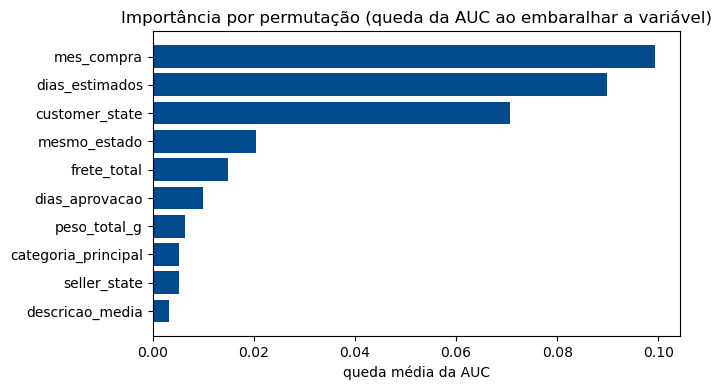

In [11]:
# TODO 3: gráfico de barras horizontais com as 10 maiores importâncias por permutação
top = importancia_perm.sort_values().tail(10)
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values, color="#014A8E")
plt.title("Importância por permutação (queda da AUC ao embaralhar a variável)"); plt.xlabel("queda média da AUC")
plt.tight_layout(); plt.show()

## 6. Validação cruzada e busca em grade

O conjunto de teste fica de fora: a escolha de hiperparâmetros usa só o treino, dividido em folds.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
scores = cross_val_score(Pipeline([("pre", criar_preprocessador_arvore()), ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEMENTE))]),
                         X_treino, y_treino, cv=cv, scoring="roc_auc")
print("AUC por fold:", scores.round(4), f"| média {scores.mean():.3f} ± {scores.std():.3f}")

t0 = time.time()
grade = {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [20, 100]}
busca = GridSearchCV(Pipeline([("pre", criar_preprocessador_arvore()), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEMENTE))]),
                     grade, cv=3, scoring="roc_auc", n_jobs=-1).fit(X_treino, y_treino)
print(f"\n{time.time() - t0:.0f} s | melhor: {busca.best_params_} | AUC de validação {busca.best_score_:.3f}")
print(pd.DataFrame(busca.cv_results_)[["param_clf__max_depth", "param_clf__min_samples_leaf", "mean_test_score", "std_test_score"]].round(4).to_string(index=False))
res_arvore_ajustada, _ = avaliar("Árvore ajustada (teste)", busca.best_estimator_)

AUC por fold: [0.724  0.7092 0.7218 0.715  0.7131] | média 0.717 ± 0.005

8 s | melhor: {'clf__max_depth': 8, 'clf__min_samples_leaf': 100} | AUC de validação 0.740
 param_clf__max_depth  param_clf__min_samples_leaf  mean_test_score  std_test_score
                    3                           20           0.6728          0.0112
                    3                          100           0.6728          0.0112
                    5                           20           0.7146          0.0067
                    5                          100           0.7149          0.0056
                    8                           20           0.7315          0.0038
                    8                          100           0.7401          0.0074
                   12                           20           0.7043          0.0031
                   12                          100           0.7358          0.0075
Árvore ajustada (teste)            AUC 0.740 | recall 0.618 | precisão 0.189 | 

## 7. Segundo alvo: avaliação baixa (nota 1 ou 2)

### TODO 4 - quais variáveis podem entrar agora?

A nota é dada **depois** da entrega. Acrescente `dias_entrega` e `atrasado` às variáveis numéricas e responda abaixo por que isso não é vazamento neste problema (e seria no da Aula 5).

In [13]:
# TODO 4: acrescente as duas variáveis de entrega à lista numérica
numericas_nota = numericas + [...]
X_n = df[numericas_nota + categoricas]
y_n = df["avaliacao_baixa"].astype(int)
Xn_treino, Xn_teste, yn_treino, yn_teste = train_test_split(X_n, y_n, test_size=0.2, random_state=SEMENTE, stratify=y_n)
print(f"prevalência {y_n.mean():.2%} | treino {len(yn_treino)} | teste {len(yn_teste)}")

modelos_nota = {
    "Logística": Pipeline([("pre", criar_preprocessador_linear(numericas_nota)), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Árvore profundidade 5": Pipeline([("pre", criar_preprocessador_arvore(numericas_nota)), ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEMENTE))]),
    "Random forest": Pipeline([("pre", criar_preprocessador_arvore(numericas_nota)), ("clf", RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight="balanced", random_state=SEMENTE, n_jobs=-1))]),
    "Gradient boosting": Pipeline([("pre", criar_preprocessador_arvore(numericas_nota)), ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMENTE))]),
}
resultados_nota = []
for nome, m in modelos_nota.items():
    m.fit(Xn_treino, yn_treino)
    r, _ = avaliar(nome + " - avaliação baixa", m, Xn_teste, yn_teste)
    resultados_nota.append(r)
nomes_n = [n.split("__")[1] for n in modelos_nota["Random forest"].named_steps["pre"].get_feature_names_out()]
print("\nImportância (floresta) - 8 maiores:")
print(pd.Series(modelos_nota["Random forest"].named_steps["clf"].feature_importances_, index=nomes_n).sort_values(ascending=False).head(8).round(4).to_string())

KeyError: '[Ellipsis] not in index'

**TODO 4 - Resposta** (edite esta célula): por que `dias_entrega` e `atrasado` podem entrar neste problema e não no da Aula 5? 

## 8. Ética, viés e LGPD: o modelo erra igual para todos?

Agrupamos o conjunto de teste do alvo *atraso* por região do cliente e comparamos a taxa real de atraso, a taxa prevista como risco pela random forest (limiar 0,5), o recall e a precisão.

In [16]:
regioes = {"Norte": ["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
           "Centro-Oeste": ["DF", "GO", "MS", "MT"], "Sudeste": ["ES", "MG", "RJ", "SP"], "Sul": ["PR", "RS", "SC"]}
uf_para_regiao = {uf: r for r, lista in regioes.items() for uf in lista}
pred_floresta = (prob_floresta >= 0.5).astype(int)
etica = pd.DataFrame({"regiao": X_teste["customer_state"].map(uf_para_regiao), "real": y_teste.values, "previsto": pred_floresta})
tabela = etica.groupby("regiao").apply(lambda g: pd.Series({
    "pedidos": len(g), "taxa real de atraso": g["real"].mean(), "taxa prevista como risco": g["previsto"].mean(),
    "recall": recall_score(g["real"], g["previsto"]), "precisão": precision_score(g["real"], g["previsto"], zero_division=0)}), include_groups=False)
print(tabela.round(3).to_string())

              pedidos  taxa real de atraso  taxa prevista como risco  recall  precisão
regiao                                                                                
Centro-Oeste   1179.0                0.071                     0.215   0.560     0.186
Nordeste       1813.0                0.141                     0.331   0.660     0.282
Norte           355.0                0.101                     0.090   0.444     0.500
Sudeste       13185.0                0.075                     0.134   0.473     0.265
Sul            2762.0                0.073                     0.136   0.398     0.213


**Responda (edite esta célula):**

1. O modelo marca como risco uma fração muito maior dos pedidos do Nordeste. Isso é viés do modelo, retrato da operação, ou os dois?
2. Para qual uso essa diferença é aceitável (ex.: priorizar despacho) e para qual seria discriminatória (ex.: negar venda, cobrar frete extra)?
3. Que salvaguardas a LGPD e as boas práticas pedem (finalidade, minimização, revisão humana, transparência, monitoramento)?

## 9. Atividade extra - TODO 5: ajustar a random forest com validação cruzada

Leva cerca de 2 minutos no Colab.

In [15]:
# TODO 5 (atividade extra): complete a grade e a busca
t0 = time.time()
grade_rf = {"clf__min_samples_leaf": [5,20,50], "clf__max_features": ["sqrt", 0,3]}
busca_rf = GridSearchCV(Pipeline([("pre", criar_preprocessador_arvore()),
                                  ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEMENTE, n_jobs=-1))]),
                        grade_rf, cv=3, scoring=...).fit(X_treino, y_treino)
print(f"{time.time() - t0:.0f} s | melhor: {busca_rf.best_params_} | AUC de validação {busca_rf.best_score_:.3f}")
print(pd.DataFrame(busca_rf.cv_results_)[["param_clf__min_samples_leaf", "param_clf__max_features", "mean_test_score"]].round(4).to_string(index=False))
res_floresta_ajustada, _ = avaliar("Random forest ajustada (teste)", busca_rf.best_estimator_)

final = pd.DataFrame([res_logistica, res_arvore5, res_arvore_ajustada, res_floresta, res_floresta_ajustada, res_boosting]).set_index("modelo")
print("\n", final[["AUC", "recall", "precisão"]].round(3).to_string())

InvalidParameterError: The 'cv' parameter of GridSearchCV must be an int in the range [2, inf), an object implementing 'split' and 'get_n_splits', an iterable or None. Got Ellipsis instead.

**Comentário (qual modelo levar para a Aula 7 e por quê):** 

---
Referências: Müller e Guido, cap. 2 e 5; Sharda, Delen e Turban, cap. 4 e 8; Lei 13.709/2018 (LGPD); documentação do scikit-learn.